# Perceptrón multicapa (MLP): clasificación de dígitos manuscritos con `sklearn.datasets.load_digits`

Este cuaderno diseña, entrena y evalúa una **red neuronal artificial multicapa** que reconoce dígitos escritos a mano (0–9).
Sigue la estructura del cuaderno de referencia `02_MLP_EZ_datos_sinteticos.ipynb`: se mantienen constantes todos los
hiperparámetros salvo la **función de activación de la capa oculta** (`identity`, `logistic`, `tanh` y `relu`), y se separan
entrenamiento, validación (selección del modelo) y prueba (evaluación final).

**Objetivos**
- Diseñar un MLP para un problema multiclase (10 clases) con entradas de 64 píxeles.
- Explicar brevemente las cuatro funciones de activación y su efecto sobre la red.
- Comparar precisión, calidad de las probabilidades y **tiempo de entrenamiento** de cada activación.
- Decidir, con criterios fijados de antemano, cuál activación conviene usar.

**Contenido**: 1. Datos · 2. Funciones de activación · 3. Particiones · 4. Diseño del modelo · 5. Referencia · 6. Comparación en validación · 7. Robustez (varias inicializaciones y validación cruzada) · 8. Selección · 9. Evaluación final · 10. Análisis y conclusión · 11. Inferencia.

Dependencias: NumPy, pandas, matplotlib y scikit-learn (`%pip install numpy pandas matplotlib scikit-learn`).

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             cohen_kappa_score, log_loss, confusion_matrix,
                             classification_report)

SEMILLA = 42
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
print("Versiones:", "NumPy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

Versiones: NumPy 2.4.4 | pandas 3.0.2 | scikit-learn 1.8.0


## 1. El conjunto de datos `digits`

`load_digits` contiene **1797 imágenes** de dígitos manuscritos en escala de grises de **8 × 8 píxeles**. Cada imagen se
representa como un vector de **64 características** (la intensidad de cada píxel, entre 0 y 16) y una etiqueta entre 0 y 9.
Es un problema de **clasificación multiclase con 10 clases** aproximadamente balanceadas, mucho más pequeño que MNIST,
por lo que permite entrenar y comparar varios modelos en segundos.

Forma de X: (1797, 64) | Forma de y: (1797,)
Rango de píxeles: 0.0 a 16.0
Valores no finitos: 0

 Dígito  Cantidad  Porcentaje
      0       178        9.91
      1       182       10.13
      2       177        9.85
      3       183       10.18
      4       181       10.07
      5       182       10.13
      6       181       10.07
      7       179        9.96
      8       174        9.68
      9       180       10.02


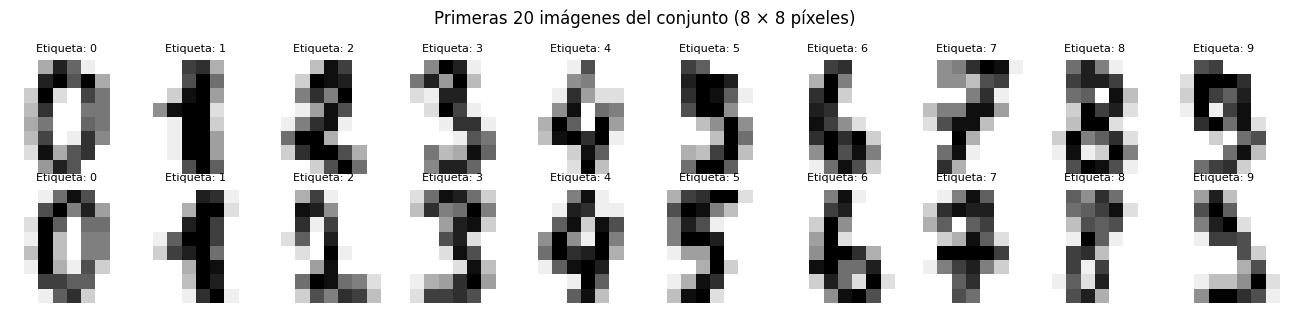

In [2]:
digitos = load_digits()
X, y = digitos.data, digitos.target
print("Forma de X:", X.shape, "| Forma de y:", y.shape)
print("Rango de píxeles:", X.min(), "a", X.max())
print("Valores no finitos:", int((~np.isfinite(X)).sum()))
print()
print(pd.DataFrame({"Dígito": np.arange(10), "Cantidad": np.bincount(y),
                    "Porcentaje": (100 * np.bincount(y) / len(y)).round(2)}).to_string(index=False))

fig, ejes = plt.subplots(2, 10, figsize=(13, 3.2))
for k, eje in enumerate(ejes.ravel()):
    eje.imshow(digitos.images[k], cmap="gray_r")
    eje.set_title(f"Etiqueta: {y[k]}", fontsize=8)
    eje.axis("off")
fig.suptitle("Primeras 20 imágenes del conjunto (8 × 8 píxeles)")
plt.tight_layout()
plt.show()

## 2. Funciones de activación de la capa oculta

Cada neurona oculta calcula primero una combinación lineal de sus entradas, $z = \mathbf{w}^\top \mathbf{x} + b$, y luego aplica una
**función de activación** $f(z)$. Sin una no linealidad, apilar capas no aporta capacidad adicional. En este cuaderno solo cambia
la activación de la capa oculta; la capa de salida usa **softmax** (10 probabilidades que suman 1).

| Activación | Fórmula | Rango | Idea principal |
| --- | --- | --- | --- |
| **identity** | $f(z)=z$ | $(-\infty,+\infty)$ | No transforma la señal: la red completa es una función **lineal**. |
| **logistic** (sigmoide) | $f(z)=\dfrac{1}{1+e^{-z}}$ | $(0,1)$ | Comprime cualquier valor a una probabilidad-like; suave, pero **satura** para $\lvert z\rvert$ grande. |
| **tanh** | $f(z)=\dfrac{e^{z}-e^{-z}}{e^{z}+e^{-z}}$ | $(-1,1)$ | Versión **centrada en cero** de la sigmoide; también satura en los extremos. |
| **relu** | $f(z)=\max(0,z)$ | $[0,+\infty)$ | Deja pasar los valores positivos y anula los negativos; barata de calcular y **no satura** para $z>0$. |

**identity.** Con esta activación, la composición de capas afines sigue siendo una transformación afín, de modo que el MLP equivale a una
regresión logística multinomial (frontera de decisión lineal), por muchas neuronas ocultas que tenga. Es útil como **línea base lineal**:
si los dígitos son casi separables linealmente, rendirá razonablemente bien, pero no puede aprender interacciones no lineales entre píxeles.

**logistic.** Es derivable en todo punto y produce salidas acotadas. Su derivada vale como máximo 0,25 y tiende a 0 cuando $\lvert z\rvert$ crece
(*saturación*), lo que puede ralentizar el aprendizaje en redes profundas (gradientes que se desvanecen). Sus salidas no están centradas en cero.

**tanh.** Tiene la misma forma de «S», pero con salida simétrica respecto de cero, lo que suele mejorar el condicionamiento de la optimización frente a
la sigmoide. Su derivada máxima es 1, aunque también satura. Requiere calcular exponenciales, más costosas que una comparación.

**relu.** Es lineal por tramos: su derivada es 0 para $z<0$ y 1 para $z>0$. Evita la saturación en la zona positiva, es la más barata de evaluar y es
el estándar en redes profundas. Su riesgo son las **neuronas muertas** (siempre con $z<0$, sin gradiente) y que no es derivable en $z=0$.

La siguiente celda dibuja las cuatro funciones y sus derivadas.

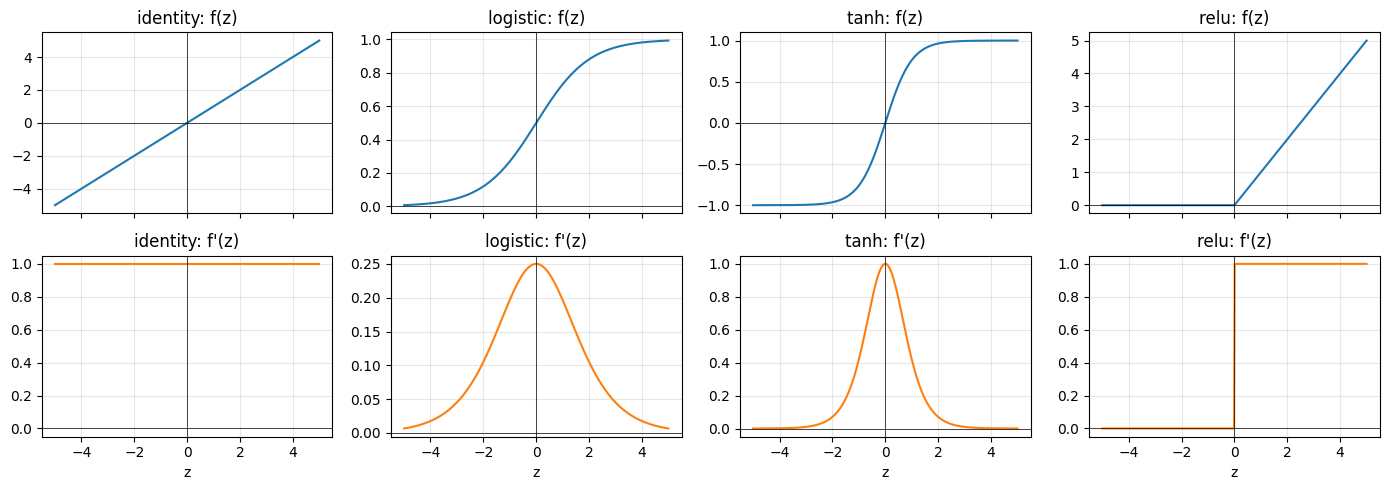

In [3]:
z = np.linspace(-5, 5, 400)
sig = 1 / (1 + np.exp(-z))
funciones = {
    "identity": (z, np.ones_like(z)),
    "logistic": (sig, sig * (1 - sig)),
    "tanh": (np.tanh(z), 1 - np.tanh(z) ** 2),
    "relu": (np.maximum(0, z), (z > 0).astype(float)),
}
fig, ejes = plt.subplots(2, 4, figsize=(14, 5), sharex=True)
for j, (nombre, (f, df)) in enumerate(funciones.items()):
    ejes[0, j].plot(z, f); ejes[0, j].set_title(f"{nombre}: f(z)")
    ejes[1, j].plot(z, df, color="tab:orange"); ejes[1, j].set_title(f"{nombre}: f'(z)")
    for e in ejes[:, j]:
        e.grid(alpha=.3); e.axhline(0, color="k", lw=.5); e.axvline(0, color="k", lw=.5)
    ejes[1, j].set_xlabel("z")
plt.tight_layout()
plt.show()

## 3. Entrenamiento, validación y prueba

Se usan particiones **estratificadas** (misma proporción de cada dígito en todas): **60 % entrenamiento**, **20 % validación** y **20 % prueba**.
La validación sirve para comparar y elegir la activación; la prueba se consulta **una sola vez**, al final, solo para el modelo elegido.

In [4]:
indices = np.arange(len(y))
i_desarrollo, i_test = train_test_split(indices, test_size=0.20, stratify=y, random_state=SEMILLA)
i_train, i_val = train_test_split(i_desarrollo, test_size=0.25, stratify=y[i_desarrollo], random_state=SEMILLA)

X_train, y_train = X[i_train], y[i_train]
X_val, y_val = X[i_val], y[i_val]
X_test, y_test = X[i_test], y[i_test]

assert not (set(i_train) & set(i_val) or set(i_train) & set(i_test) or set(i_val) & set(i_test))
assert len(set(i_train) | set(i_val) | set(i_test)) == len(y)

resumen = pd.DataFrame({
    "Entrenamiento": np.bincount(y_train), "Validación": np.bincount(y_val), "Prueba": np.bincount(y_test)
}, index=pd.Index(range(10), name="Dígito"))
resumen.loc["Total"] = resumen.sum()
print(resumen.to_string())

        Entrenamiento  Validación  Prueba
Dígito                                   
0                 106          36      36
1                 109          37      36
2                 107          35      35
3                 109          37      37
4                 109          36      36
5                 109          36      37
6                 109          36      36
7                 107          36      36
8                 104          35      35
9                 108          36      36
Total            1077         360     360


## 4. Diseño del modelo

**Arquitectura.** $64 \rightarrow 64 \rightarrow 10$: 64 entradas (píxeles), **una capa oculta de 64 neuronas** y 10 salidas con *softmax*.
Hay $64\cdot64+64 = 4160$ parámetros en la capa oculta y $64\cdot10+10 = 650$ en la salida (4810 en total).

**Preprocesamiento.** Un `StandardScaler` (media 0, desviación 1 por píxel) dentro de un `Pipeline`, de modo que se ajusta **solo con los datos de
entrenamiento** y no filtra información de validación o prueba. Los píxeles constantes (siempre 0) se dejan sin escalar de forma segura.

**Optimización.** Igual que en el cuaderno de referencia, se usa **L-BFGS**, un método cuasi-Newton que aproxima la curvatura de la función objetivo
con memoria limitada y emplea **todo el conjunto de entrenamiento en cada iteración** (sin minilotes). Es muy eficiente en conjuntos pequeños como
este. La función objetivo es la **entropía cruzada** (log loss) más una penalización L2 (`alpha=1e-4`). No garantiza el mínimo global: la pérdida del MLP es no convexa,
por lo que el resultado depende de la inicialización (`random_state`).

**Hiperparámetros constantes en todos los modelos:** `hidden_layer_sizes=(64,)`, `solver="lbfgs"`, `alpha=1e-4`, `tol=1e-6`, `max_iter=2000`.
Solo cambia `activation`.

**Métricas.**
- *Accuracy*: proporción total de aciertos.
- *Balanced accuracy*: promedio del recall de cada dígito (robusta a pequeños desbalances).
- *F1 macro*: promedio del F1 de las 10 clases.
- *Kappa*: acuerdo corregido por el azar.
- *Log loss*: calidad de las probabilidades; penaliza fuertemente errores muy confiados (menor es mejor).
- *Tiempo de entrenamiento* e *iteraciones* de L-BFGS.

In [5]:
def evaluar(modelo, entradas, etiquetas):
    pred = modelo.predict(entradas)
    proba = modelo.predict_proba(entradas)
    return {
        "Accuracy": accuracy_score(etiquetas, pred),
        "Balanced accuracy": balanced_accuracy_score(etiquetas, pred),
        "F1 macro": f1_score(etiquetas, pred, average="macro", zero_division=0),
        "Kappa": cohen_kappa_score(etiquetas, pred),
        "Log loss": log_loss(etiquetas, proba, labels=modelo.classes_),
    }

def construir_mlp(activacion, semilla=SEMILLA):
    return Pipeline([
        ("escala", StandardScaler()),
        ("mlp", MLPClassifier(hidden_layer_sizes=(64,), activation=activacion,
                              solver="lbfgs", alpha=1e-4, tol=1e-6,
                              max_iter=2000, random_state=semilla)),
    ])

def entrenar(activacion, semilla=SEMILLA):
    # Entrena un modelo y devuelve (modelo, segundos, advertencias de convergencia).
    modelo = construir_mlp(activacion, semilla)
    inicio = time.perf_counter()
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always", ConvergenceWarning)
        modelo.fit(X_train, y_train)
    segundos = time.perf_counter() - inicio
    mensajes = [str(a.message) for a in avisos if issubclass(a.category, ConvergenceWarning)]
    return modelo, segundos, mensajes

# Calentamiento: el primer ajuste de la sesión incluye cargas de módulos y caché fríos
# (casi el doble de tiempo). Se hace uno descartable para que ninguna activación
# resulte penalizada por el orden en que se entrena.
_ = entrenar("tanh", semilla=999)

## 5. Referencia mínima

Un clasificador que siempre predice la clase más frecuente sirve como punto de comparación. Con 10 clases casi balanceadas, su accuracy es
cercano al 10 %: cualquier modelo útil debe superarlo ampliamente.

In [6]:
referencia = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Referencia (clase mayoritaria) en validación:")
print(pd.Series(evaluar(referencia, X_val, y_val)).round(4).to_string())

Referencia (clase mayoritaria) en validación:
Accuracy              0.1028
Balanced accuracy     0.1000
F1 macro              0.0186
Kappa                 0.0000
Log loss             32.3392


## 6. Comparación controlada en validación

Se entrena un modelo por activación (misma semilla, mismas particiones y mismos hiperparámetros) y se registran el desempeño en entrenamiento y validación,
el número de iteraciones, las advertencias de convergencia y el tiempo de ajuste (que incluye el escalado, de coste despreciable; antes de medir se hizo un ajuste de calentamiento).

In [7]:
ACTIVACIONES = ["identity", "logistic", "tanh", "relu"]
modelos, filas, avisos_por_modelo = {}, [], {}
for act in ACTIVACIONES:
    modelo, segundos, mensajes = entrenar(act)
    tr = evaluar(modelo, X_train, y_train)
    va = evaluar(modelo, X_val, y_val)
    filas.append({"Activación": act, "Accuracy train": tr["Accuracy"], **va,
                  "Iteraciones": modelo.named_steps["mlp"].n_iter_,
                  "Aviso convergencia": bool(mensajes), "Segundos": segundos})
    modelos[act], avisos_por_modelo[act] = modelo, mensajes

resultados = pd.DataFrame(filas).set_index("Activación")
print("Métricas de validación (salvo 'Accuracy train'):")
print(resultados.round(4).to_string())

Métricas de validación (salvo 'Accuracy train'):
            Accuracy train  Accuracy  Balanced accuracy  F1 macro   Kappa  Log loss  Iteraciones  Aviso convergencia  Segundos
Activación                                                                                                                    
identity               1.0    0.9528             0.9527    0.9525  0.9475    0.5020           24               False    0.0526
logistic               1.0    0.9750             0.9750    0.9752  0.9722    0.1042           44               False    0.1160
tanh                   1.0    0.9667             0.9665    0.9667  0.9630    0.1345           19               False    0.0452
relu                   1.0    0.9611             0.9609    0.9611  0.9568    0.1905           23               False    0.0540


Un accuracy de entrenamiento cercano al 100 % con una validación menor indica cierto **sobreajuste**: es esperable con 64 neuronas ocultas, 64 entradas y solo ~1080 ejemplos de entrenamiento.
Una sola ejecución depende de la inicialización aleatoria y, además, los tiempos de una fracción de segundo son ruidosos. Por eso se repite el experimento en la siguiente sección.

## 7. Robustez: varias inicializaciones

Se repite el entrenamiento con **10 semillas** distintas para cada activación (mismas particiones; cambia solo la inicialización de los pesos).
Se informan la media y la desviación estándar del desempeño en validación y del tiempo de entrenamiento (además, la **mediana** del tiempo, menos sensible a un ajuste puntualmente lento). Así se evita decidir a partir de una única inicialización favorable.

In [8]:
SEMILLAS = list(range(10))
registros = []
for act in ACTIVACIONES:
    for s in SEMILLAS:
        modelo, segundos, mensajes = entrenar(act, semilla=s)
        va = evaluar(modelo, X_val, y_val)
        registros.append({"Activación": act, "Semilla": s, **va,
                          "Iteraciones": modelo.named_steps["mlp"].n_iter_,
                          "Avisos": int(bool(mensajes)), "Segundos": segundos})
repeticiones = pd.DataFrame(registros)

resumen_rep = repeticiones.groupby("Activación").agg(
    acc_media=("Accuracy", "mean"), acc_std=("Accuracy", "std"),
    bal_media=("Balanced accuracy", "mean"),
    f1_media=("F1 macro", "mean"),
    logloss_media=("Log loss", "mean"),
    iter_media=("Iteraciones", "mean"),
    seg_media=("Segundos", "mean"), seg_mediana=("Segundos", "median"), seg_std=("Segundos", "std"),
    avisos=("Avisos", "sum"),
).loc[ACTIVACIONES]
print(f"Resumen sobre {len(SEMILLAS)} inicializaciones (validación):")
print(resumen_rep.round(4).to_string())

Resumen sobre 10 inicializaciones (validación):
            acc_media  acc_std  bal_media  f1_media  logloss_media  iter_media  seg_media  seg_mediana  seg_std  avisos
Activación                                                                                                             
identity       0.9511   0.0042     0.9510    0.9508         0.4844        24.2     0.0493       0.0482   0.0055       0
logistic       0.9772   0.0061     0.9772    0.9773         0.0829        42.7     0.1084       0.1095   0.0141       0
tanh           0.9717   0.0039     0.9715    0.9716         0.1046        20.2     0.0485       0.0453   0.0070       0
relu           0.9689   0.0069     0.9687    0.9688         0.1967        22.6     0.0553       0.0546   0.0022       0


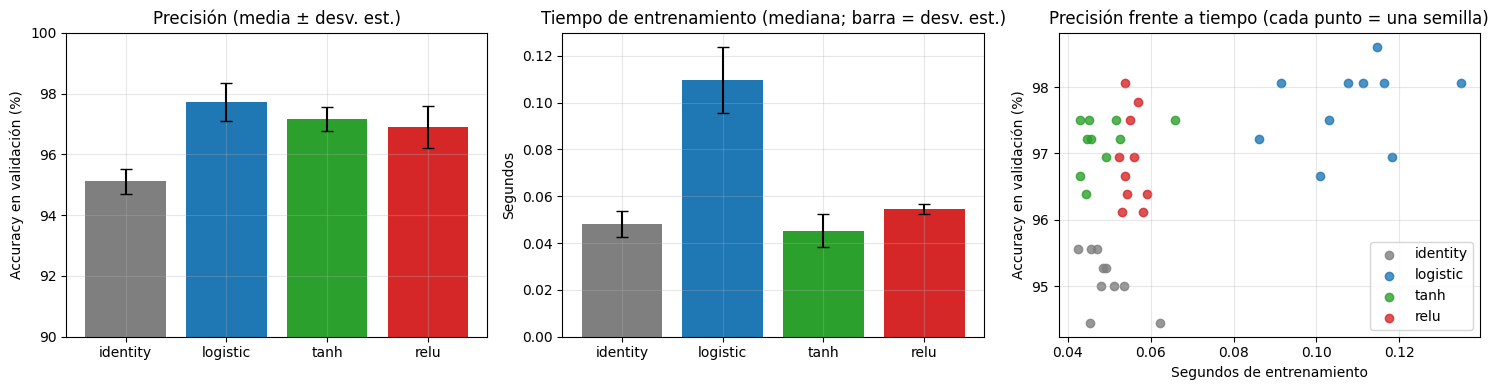

In [9]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
colores = ["tab:gray", "tab:blue", "tab:green", "tab:red"]

ejes[0].bar(ACTIVACIONES, 100 * resumen_rep["acc_media"], yerr=100 * resumen_rep["acc_std"], color=colores, capsize=4)
ejes[0].set_ylim(90, 100); ejes[0].set_ylabel("Accuracy en validación (%)")
ejes[0].set_title("Precisión (media ± desv. est.)")

ejes[1].bar(ACTIVACIONES, resumen_rep["seg_mediana"], yerr=resumen_rep["seg_std"], color=colores, capsize=4)
ejes[1].set_ylabel("Segundos"); ejes[1].set_title("Tiempo de entrenamiento (mediana; barra = desv. est.)")

for act, c in zip(ACTIVACIONES, colores):
    sub = repeticiones[repeticiones["Activación"] == act]
    ejes[2].scatter(sub["Segundos"], 100 * sub["Accuracy"], color=c, label=act, alpha=.8)
ejes[2].set_xlabel("Segundos de entrenamiento"); ejes[2].set_ylabel("Accuracy en validación (%)")
ejes[2].set_title("Precisión frente a tiempo (cada punto = una semilla)"); ejes[2].legend()
for e in ejes: e.grid(alpha=.3)
plt.tight_layout()
plt.show()

### 7.1 Comprobación con validación cruzada

Las 10 semillas solo varían la inicialización; la partición de validación (360 ejemplos) es siempre la misma, y una sola partición puede favorecer a una activación por azar.
Como comprobación adicional se usa **validación cruzada estratificada de 5 pliegues** sobre el conjunto de desarrollo (entrenamiento + validación; la prueba sigue sin tocarse).
Cada activación se evalúa en 5 particiones distintas. Esta sección **no cambia** la regla de selección: sirve para verificar que el orden observado no depende de una partición concreta.

In [10]:
from sklearn.model_selection import StratifiedKFold, cross_validate

X_dev, y_dev = X[i_desarrollo], y[i_desarrollo]
pliegues = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
filas_cv = []
for act in ACTIVACIONES:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        cv = cross_validate(construir_mlp(act), X_dev, y_dev, cv=pliegues,
                            scoring=["accuracy", "neg_log_loss"])
    filas_cv.append({"Activación": act,
                     "Accuracy media": cv["test_accuracy"].mean(),
                     "Accuracy desv.": cv["test_accuracy"].std(),
                     "Log loss medio": -cv["test_neg_log_loss"].mean(),
                     "Seg. por ajuste (mediana)": np.median(cv["fit_time"])})
resultados_cv = pd.DataFrame(filas_cv).set_index("Activación")
print("Validación cruzada de 5 pliegues (entrenamiento + validación):")
print(resultados_cv.round(4).to_string())

Validación cruzada de 5 pliegues (entrenamiento + validación):
            Accuracy media  Accuracy desv.  Log loss medio  Seg. por ajuste (mediana)
Activación                                                                           
identity            0.9589          0.0092          0.5426                     0.0488
logistic            0.9763          0.0071          0.1221                     0.1345
tanh                0.9701          0.0056          0.1931                     0.0478
relu                0.9673          0.0097          0.2433                     0.0635


## 8. Selección de la activación

La regla se fija **antes** de mirar la prueba y considera la precisión y el tiempo, como pide el enunciado:

1. Se calcula la **balanced accuracy media de validación** (sobre las 10 inicializaciones) de cada activación.
2. Se consideran *competitivas* las activaciones cuya media está a **menos de 1 punto porcentual** de la mejor (diferencias menores quedan dentro del ruido entre semillas).
3. Entre las competitivas se elige la de **menor tiempo mediano de entrenamiento**.

Después se entrena el modelo elegido con la semilla de referencia (`SEMILLA = 42`) y se evalúa una sola vez en prueba.

In [11]:
tabla_sel = resumen_rep[["bal_media", "logloss_media", "seg_mediana"]].copy()
mejor_bal = tabla_sel["bal_media"].max()
tabla_sel["Competitiva"] = tabla_sel["bal_media"] >= mejor_bal - 0.01
competitivas = tabla_sel[tabla_sel["Competitiva"]]
mejor_activacion = competitivas["seg_mediana"].idxmin()

print(tabla_sel.round(4).to_string())
print("\nActivación seleccionada:", mejor_activacion)

mejor_modelo = modelos[mejor_activacion]   # entrenado con la semilla 42 en la sección 6
if avisos_por_modelo[mejor_activacion]:
    print("ATENCIÓN: el modelo seleccionado tiene advertencias de convergencia.")

ACTIVACION_ANALIZADA = "tanh"   # la activación sobre la que se redactó la sección 10
if mejor_activacion != ACTIVACION_ANALIZADA:
    print(f"AVISO: en esta ejecución se seleccionó '{mejor_activacion}', pero el análisis de la "
          f"sección 10 se redactó para '{ACTIVACION_ANALIZADA}' (los tiempos varían con el hardware). "
          "Revise ese texto antes de usarlo.")

            bal_media  logloss_media  seg_mediana  Competitiva
Activación                                                    
identity       0.9510         0.4844       0.0482        False
logistic       0.9772         0.0829       0.1095         True
tanh           0.9715         0.1046       0.0453         True
relu           0.9687         0.1967       0.0546         True

Activación seleccionada: tanh


## 9. Evaluación final en prueba

El modelo elegido se evalúa en los 360 ejemplos de prueba, que no intervinieron en ningún entrenamiento ni decisión. Se compara con la referencia mayoritaria,
se muestra la matriz de confusión (filas: dígito real; columnas: dígito predicho) y se visualizan los errores.

In [12]:
comparacion_test = pd.DataFrame({
    "Referencia mayoritaria": evaluar(referencia, X_test, y_test),
    f"MLP ({mejor_activacion})": evaluar(mejor_modelo, X_test, y_test),
}).T
print(comparacion_test.round(4).to_string())

y_pred_test = mejor_modelo.predict(X_test)
print("\nInforme por clase:")
print(classification_report(y_test, y_pred_test, digits=4, zero_division=0))

                        Accuracy  Balanced accuracy  F1 macro  Kappa  Log loss
Referencia mayoritaria    0.1000             0.1000    0.0182  0.000   32.4393
MLP (tanh)                0.9694             0.9691    0.9689  0.966    0.1539

Informe por clase:
              precision    recall  f1-score   support

           0     1.0000    0.9722    0.9859        36
           1     0.9143    0.8889    0.9014        36
           2     0.9211    1.0000    0.9589        35
           3     1.0000    1.0000    1.0000        37
           4     1.0000    1.0000    1.0000        36
           5     1.0000    1.0000    1.0000        37
           6     1.0000    1.0000    1.0000        36
           7     0.9474    1.0000    0.9730        36
           8     0.9394    0.8857    0.9118        35
           9     0.9714    0.9444    0.9577        36

    accuracy                         0.9694       360
   macro avg     0.9694    0.9691    0.9689       360
weighted avg     0.9697    0.9694    0.

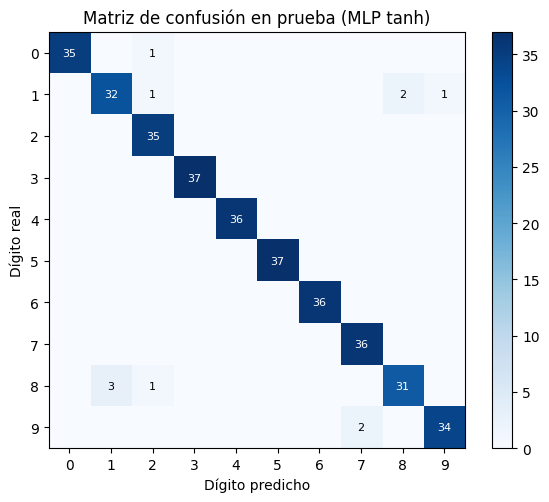

Errores en prueba: 11 de 360


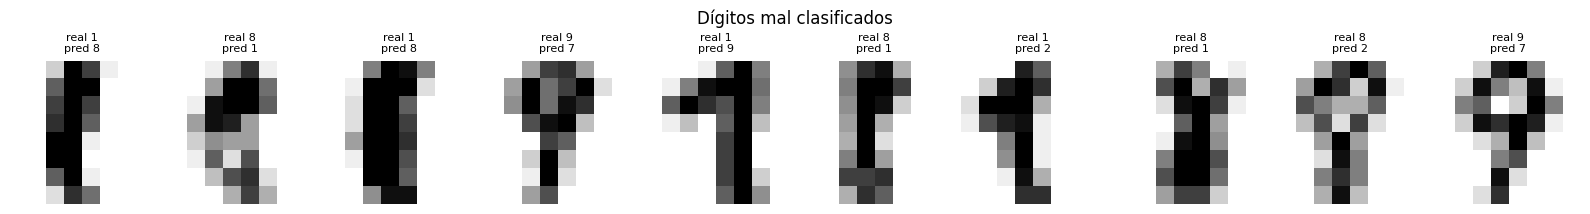

In [13]:
matriz = confusion_matrix(y_test, y_pred_test, labels=range(10))
fig, eje = plt.subplots(figsize=(6, 5))
im = eje.imshow(matriz, cmap="Blues")
eje.set_xticks(range(10)); eje.set_yticks(range(10))
eje.set_xlabel("Dígito predicho"); eje.set_ylabel("Dígito real")
eje.set_title(f"Matriz de confusión en prueba (MLP {mejor_activacion})")
for i in range(10):
    for j in range(10):
        if matriz[i, j]:
            eje.text(j, i, matriz[i, j], ha="center", va="center",
                     color="white" if matriz[i, j] > matriz.max() / 2 else "black", fontsize=8)
plt.colorbar(im); plt.tight_layout(); plt.show()

errores = np.flatnonzero(y_pred_test != y_test)
print(f"Errores en prueba: {len(errores)} de {len(y_test)}")
if len(errores):
    mostrar = errores[:10]
    fig, ejes = plt.subplots(1, len(mostrar), figsize=(1.6 * len(mostrar), 2.2), squeeze=False)
    for eje, k in zip(ejes[0], mostrar):
        eje.imshow(X_test[k].reshape(8, 8), cmap="gray_r"); eje.axis("off")
        eje.set_title(f"real {y_test[k]}\npred {y_pred_test[k]}", fontsize=8)
    plt.suptitle("Dígitos mal clasificados"); plt.tight_layout(); plt.show()

## 10. Análisis de resultados y conclusión

**Resultados principales** (validación, media de 10 inicializaciones; el tiempo es la mediana, tras un ajuste de calentamiento; los valores dependen de la máquina):

| Activación | Accuracy val. | Log loss val. | Iteraciones L-BFGS | Tiempo mediano |
| --- | ---: | ---: | ---: | ---: |
| identity | ≈ 95,1 % | ≈ 0,48 | ≈ 24 | ≈ 0,05 s |
| logistic | ≈ 97,7 % | ≈ 0,08 | ≈ 43 | ≈ 0,11–0,12 s |
| tanh | ≈ 97,2 % | ≈ 0,10 | ≈ 20 | ≈ 0,05 s |
| relu | ≈ 96,9 % | ≈ 0,20 | ≈ 23 | ≈ 0,06 s |

**Análisis por activación**

- **identity.** Es la más rápida junto con tanh, pero la menos precisa (≈ 95 %) y con probabilidades mucho peores (log loss ≈ 0,48, entre 2,5 y 6 veces el de las demás). Que alcance 95 % con un modelo equivalente a una regresión logística multinomial muestra que `digits` es casi linealmente separable; la brecha de ≈ 2 puntos frente a las no lineales es la ganancia de modelar interacciones entre píxeles.
- **logistic.** Obtiene la mejor precisión media y el mejor log loss (probabilidades más fiables), pero necesita unas dos veces las iteraciones de las demás y más del doble de tiempo que tanh. Es coherente con su saturación y su salida no centrada en cero, que hacen más lenta la optimización.
- **tanh.** Alcanza una precisión casi igual a la de logistic (diferencia ≈ 0,5 puntos, del orden de la variación entre semillas) con la mitad de las iteraciones; su salida centrada en cero favorece una convergencia más rápida. Además, es la que muestra menor variación de precisión entre inicializaciones.
- **relu.** Es rápida y precisa, pero queda ligeramente por debajo de tanh y logistic en accuracy y tiene un log loss casi el doble que tanh. Sus ventajas (no saturar, bajo coste por evaluación) importan sobre todo en redes profundas y conjuntos grandes; aquí, con una sola capa oculta y 64 entradas, apenas se aprovechan.

**Observaciones generales**

- Todos los modelos alcanzan ≈ 100 % de accuracy en entrenamiento: hay **sobreajuste moderado**, esperable con 4810 parámetros y ≈ 1077 ejemplos. La comparación válida es la de validación.
- La **validación cruzada de 5 pliegues** (sección 7.1) reproduce el mismo orden: logistic (≈ 97,6 %) > tanh (≈ 97,0 %) > relu (≈ 96,7 %) > identity (≈ 95,9 %), y tiempos con el mismo patrón (logistic es la más lenta; tanh e identity, las más rápidas y prácticamente empatadas). Esto indica que el resultado no depende de la partición de validación elegida. Su log loss es mayor porque cada pliegue entrena con menos datos.
- Ningún entrenamiento produjo advertencias de convergencia; L-BFGS se detuvo por tolerancia en 20–45 iteraciones.
- Con L-BFGS el tiempo es aproximadamente *iteraciones × coste por iteración*. Las diferencias absolutas son de décimas de segundo porque el problema es pequeño; en datos mayores serían más relevantes, pero la ordenación podría cambiar (solver, tamaño de la red).
- Las diferencias entre logistic, tanh y relu en accuracy son pequeñas (≤ 1 punto) frente a la variación entre semillas (desv. est. ≈ 0,4–0,7 puntos) y se calculan con una única partición de 360 ejemplos de validación, de modo que **no deben interpretarse como superioridad general**.

**Decisión: tanh**

Aplicando la regla fijada en la sección 8, identity queda descartada por precisión; logistic, tanh y relu son competitivas (a menos de 1 punto de la mejor) y, entre ellas, **tanh** es la de menor tiempo mediano de entrenamiento. Es la activación que más conviene por su equilibrio:

- precisión prácticamente equivalente a la mejor (≈ 97 %);
- tiempo de entrenamiento entre el menor y similar al de identity, y menos de la mitad del de logistic;
- probabilidades bastante mejores que las de relu e identity, y estabilidad entre inicializaciones.

Si lo prioritario fuera **la máxima calidad de las probabilidades** y el tiempo no importara (la diferencia absoluta es de ≈ 0,06 s), **logistic** sería una alternativa razonable; si el problema creciera hacia redes profundas o datos grandes, **relu** sería la opción habitual.

En prueba, el MLP con tanh alcanza ≈ 97 % de accuracy frente al 10 % de la referencia, con unos 11 errores de 360. Los errores se concentran en los dígitos 1, 8 y 9 (por ejemplo, 1 ↔ 8 y 9 → 7), formas que pueden parecerse a 8 × 8 píxeles. Los valores exactos de las tablas pueden variar ligeramente con las versiones de las librerías y, en el caso de los tiempos, con el hardware.

## 11. Inferencia con el modelo elegido

Se clasifican cinco imágenes del conjunto de prueba mostrando la probabilidad asignada a la clase predicha. Las columnas de `predict_proba` siguen el orden de `classes_`.

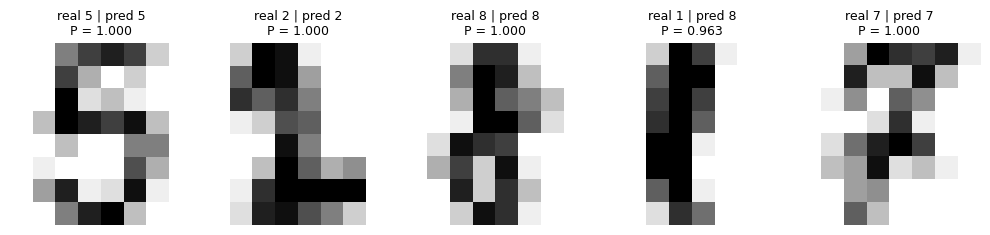

In [14]:
muestra_idx = np.arange(5)
proba = mejor_modelo.predict_proba(X_test[muestra_idx])
pred = mejor_modelo.classes_[proba.argmax(axis=1)]

fig, ejes = plt.subplots(1, 5, figsize=(10, 2.6))
for eje, k, p, pr in zip(ejes, muestra_idx, pred, proba.max(axis=1)):
    eje.imshow(X_test[k].reshape(8, 8), cmap="gray_r"); eje.axis("off")
    eje.set_title(f"real {y_test[k]} | pred {p}\nP = {pr:.3f}", fontsize=9)
plt.tight_layout(); plt.show()